# an0065@uah.edu
# https://github.com/zippermergegh/zippermerge

# 1. Locally-weighted Regression

Residual vector is $e=y-Xw$ and $A$ is diagonal:

$$\sum_{i=1}^N a^{(i)}\left(y^{(i)}-w^\top{x}^{(i)}\right)^2=\sum_{i=1}^N e_i\,{A}_{ii}\,e_i={e}^\top{A}\,{e}$$

$\|w\|^2=w^\top{w}$, so

$$J(w) = \frac{1}{2}(y-Xw)^\top{A}(y-Xw) + \frac{\lambda}{2}w^\top{w}$$

$$J(w) = \frac{1}{2}\left[y^\top{A}y - y^\top{A}Xw - w^\top{X}^\top{A}y + w^\top{X}^\top{A}Xw\right] + \frac{\lambda}{2}w^\top{w}$$

$$J(w) = \frac{1}{2}y^\top{A}y - w^\top{X}^\top{A}y + \frac{1}{2}w^\top{X}^\top{A}Xw + \frac{\lambda}{2}w^\top{w}$$

Using $\nabla_{w}(b^\top{w})=b$ and $\nabla_w(w^\top{M}w)=2Mw$ for symmetric $M$ since both $X^\top{A}X$ and $I$ are symmetric:

$$\nabla_w J(w) = -X^\top{A}y + X^\top{A}Xw + \lambda{w} = 0$$

$$\left(X^\top{A}X + \lambda{I}\right)w = X^\top{A}y$$

$$\hat{w} = (X^\top{A}X+\lambda{I})^{-1}X^\top{A}y$$

# 2. Logistic Regression by Hand

## Question 1

| $i$ | $z^{(i)}=1.5x_1+2x_2+1x_3$ | $h_{{\theta}}({x}^{(i)})=\dfrac{1}{1+e^{-z}}$ |
|---|---|---|
| 1 | $1$ | $0.7311$ |
| 2 | $2$ | $0.8808$ |
| 3 | $3$ | $0.9526$ |
| 4 | $1.5$ | $0.8176$ |

$i=1$, $y=0$: $-\ln(1-0.7311)=1.3133$
$i=2$, $y=1$: $-\ln(0.8808)=0.1269$
$i=3$, $y=1$: $-\ln(0.9526)=0.0486$
$i=4$, $y=0$: $-\ln(1-0.8176)=1.7014$

$$J({\theta})=\frac{1.3133+0.1269+0.0486+1.7014}{4}=\frac{3.1902}{4}\approx {0.7975}$$

## Question 2

Log-likelihood gradient:

$$\frac{\partial LL({\theta})}{\partial\theta_j}=\sum_{i=1}^{N}\left[y^{(i)}-h_{{\theta}}({x}^{(i)})\right]x_j^{(i)}$$

$J=-\frac{1}{N}LL$:

$$\frac{\partial J({\theta})}{\partial\theta_j}=\frac{1}{N}\sum_{i=1}^{N}\left[h_{{\theta}}({x}^{(i)})-y^{(i)}\right]x_j^{(i)}$$

Errors $h-y$: $[\,0.7311,\;-0.1192,\;-0.0474,\;0.8176\,]$ for $i=1,2,3,4$

$j=1$ (only $i=4$ has $x_1=1$): $\dfrac{0.8176}{4}={0.2044}$

$j=2$ ($i=2,3$): $\dfrac{-0.1192-0.0474}{4}={-0.0417}$

$j=3$ ($i=1,3$): $\dfrac{0.7311-0.0474}{4}={0.1709}$

Vector form: $\nabla J=\frac{1}{N}{X}^\top({h}-{y})=[0.2044,\,-0.0417,\,0.1709]^\top$

## Question 3

$$\theta_j\leftarrow\theta_j-\eta\frac{\partial J}{\partial\theta_j}$$

$\theta_1 = 1.5-0.2044 = 1.2956$

$\theta_2 = 2-(-0.0417) = 2.0417$

$\theta_3 = 1-0.1709 = 0.8291$

$${{\theta}_{\text{new}}=[1.2956,\;2.0417,\;0.8291]^\top}$$



# 3. How is Logistic Regression different from Polynomial Regression?

Polynomial regression predicts a continuous number, while logistic regression predicts the probability that an example belongs to a class. The models, errors, and loss are calculated differently as a result, and polynomical regression has a closed form, while logistic does not.

# 4. Assumptions and Diagnostics in Linear Regression

## Question 1

The errors have constant variance across all values of the predictor in homoscedasticity. To detect this, you would fit the model and compute $e = y - \hat{y}$. Then, plot the residuals $e$ against the predictor $x$, with a reference line at $e=0$. If it is homoscedastic, the residuals form a uniform horizontal band around zero, with the same vertical spread everywhere.

## Question 2

The errors are zero-mean, constant-variance Gaussian in Normality of Errors. To detect this, plot $e$ against $x$. Under normality the points scatter symmetrically around zero, with most near zero and few far from it. It should also look like a symmetric bell curve centered at 0. Skewness, heavy tails, or multiple peaks would show a violation.

## Question 3

If the predictor variables are correlated with each other, multicollinearity exists. To detect this, you would plot every predictor against every other. A clear linear trend between two predictors would signal collinearity.

# 5. Multiple Regression

## Question 1

In [5]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 15

os.makedirs('figures', exist_ok=True)

URL = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    try:
        df = pd.read_csv("Folds5x2_pp.csv")
    except Exception:
        from google.colab import files
        up = files.upload()
        df = pd.read_csv(next(iter(up)))
df.head()

features = ["AT", "V", "AP", "RH"]
X = df[features].values
y = df["PE"].values

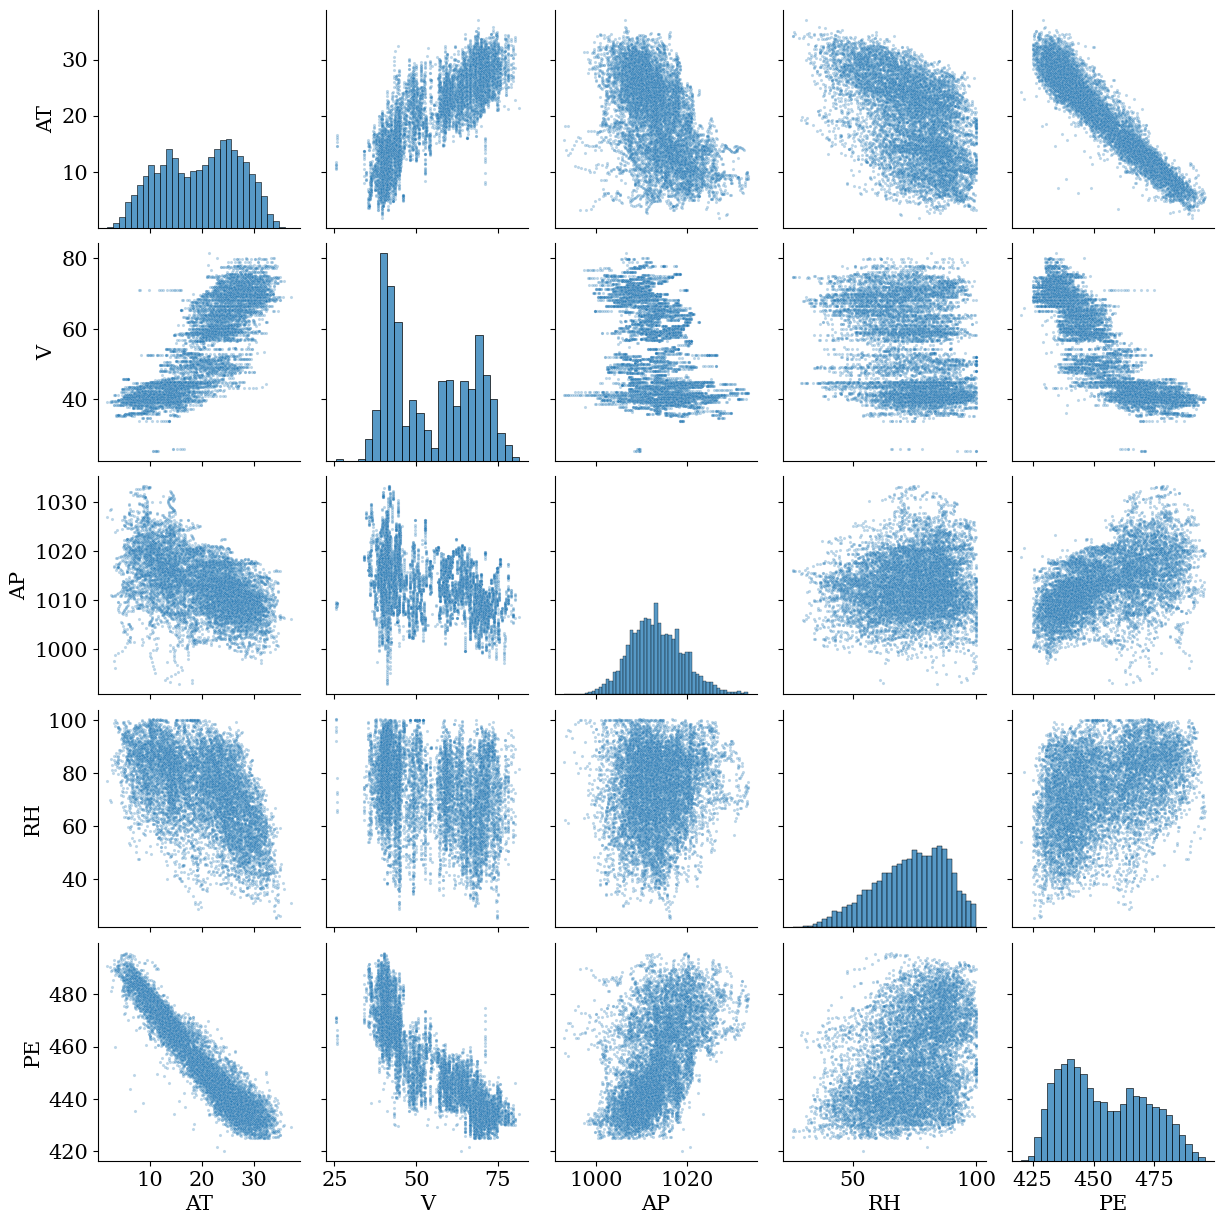

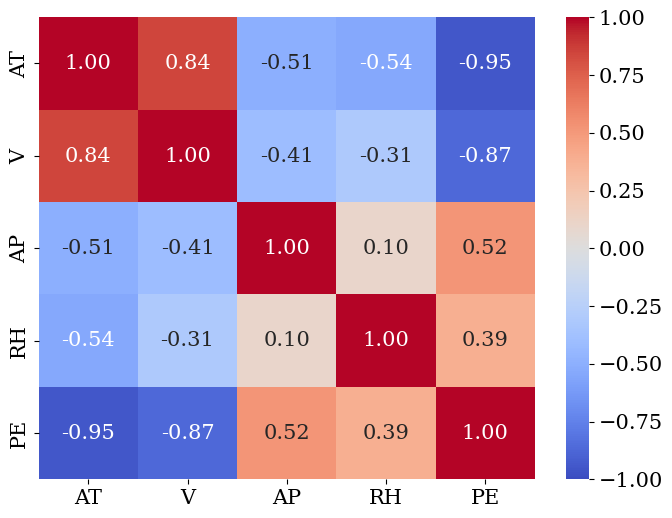

In [4]:
g = sns.pairplot(df, plot_kws={'alpha': 0.3, 's': 5})
g.savefig('figures/scatterplot_matrix_power_plant.pdf', format='pdf', bbox_inches='tight')
plt.show()

plt.figure(figsize=(8,6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.savefig('figures/correlation_heatmap_power_plant.pdf', format='pdf', bbox_inches='tight')
plt.show()

## Question 2

In [7]:
class CauchyRegression:
    def __init__(self, c=1.0, lr=0.05, epochs=5000, beta1=0.9, beta2=0.999, eps=1e-8):
        self.c, self.lr, self.epochs = c, lr, epochs
        self.beta1, self.beta2, self.eps = beta1, beta2, eps

    # ---- loss and gradient on the standardized design matrix Xb = [1, Z] ----
    def _loss_s(self, Xb, y, w):
        r = y - Xb @ w
        return np.mean(self.c**2 / 2 * np.log1p((r / self.c) ** 2))

    def _grad_s(self, Xb, y, w):
        r = y - Xb @ w
        psi = r / (1 + (r / self.c) ** 2)          # d loss / d r
        return -Xb.T @ psi / len(y)                # chain rule: dr/dw = -x

    def _to_std(self, w):
        ws = np.empty_like(w)
        ws[1:] = w[1:] * self.sd_
        ws[0] = w[0] + np.sum(w[1:] * self.mu_)
        return ws

    def fit(self, X, y, w_init=None, record=True):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.mu_, self.sd_ = X.mean(0), X.std(0)
        Xb = np.column_stack([np.ones(len(y)), (X - self.mu_) / self.sd_])

        # intercept starts at median(y), slopes at 0 (the Cauchy gradient vanishes for huge residuals)
        w = np.r_[np.median(y), np.zeros(X.shape[1])] if w_init is None else self._to_std(np.asarray(w_init, float))
        m, v = np.zeros_like(w), np.zeros_like(w)
        self.loss_history_ = []
        for t in range(1, self.epochs + 1):             # full-batch Adam
            g = self._grad_s(Xb, y, w)
            m = self.beta1 * m + (1 - self.beta1) * g
            v = self.beta2 * v + (1 - self.beta2) * g * g
            w = w - self.lr * (m / (1 - self.beta1**t)) / (np.sqrt(v / (1 - self.beta2**t)) + self.eps)
            if record:
                self.loss_history_.append(self._loss_s(Xb, y, w))
        self.w_std_ = w
        # convert back to the original feature units
        self.coef_ = w[1:] / self.sd_
        self.intercept_ = w[0] - np.sum(w[1:] * self.mu_ / self.sd_)
        self.w_ = np.r_[self.intercept_, self.coef_]
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, float) @ self.coef_

    def loss(self, X, y, total=False):
        r = np.asarray(y, float) - self.predict(X)
        l = self.c**2 / 2 * np.log1p((r / self.c) ** 2)
        return l.sum() if total else l.mean()

    def conf_int(self, X, y, level=0.95):
        """Asymptotic (sandwich) confidence intervals for an M-estimator: H^-1 B H^-1 / n."""
        X, y = np.asarray(X, float), np.asarray(y, float)
        n, c = len(y), self.c
        Xb = np.column_stack([np.ones(n), (X - self.mu_) / self.sd_])
        r = y - Xb @ self.w_std_
        psi = r / (1 + (r / c) ** 2)
        dpsi = (1 - (r / c) ** 2) / (1 + (r / c) ** 2) ** 2     # second derivative of the loss in r
        H = (Xb * dpsi[:, None]).T @ Xb / n
        B = (Xb * (psi ** 2)[:, None]).T @ Xb / n
        Hinv = np.linalg.inv(H)
        cov_std = Hinv @ B @ Hinv / n
        # map covariance from standardized parameters back to original units
        T = np.zeros((X.shape[1] + 1,) * 2)
        T[0, 0] = 1; T[0, 1:] = -self.mu_ / self.sd_
        T[1:, 1:] = np.diag(1 / self.sd_)
        se = np.sqrt(np.diag(T @ cov_std @ T.T))
        z = stats.norm.ppf(0.5 + level / 2)
        return self.w_ - z * se, self.w_ + z * se, se

In [8]:
model = CauchyRegression(c=1.0, lr=0.05, epochs=5000)
model.fit(X, y)

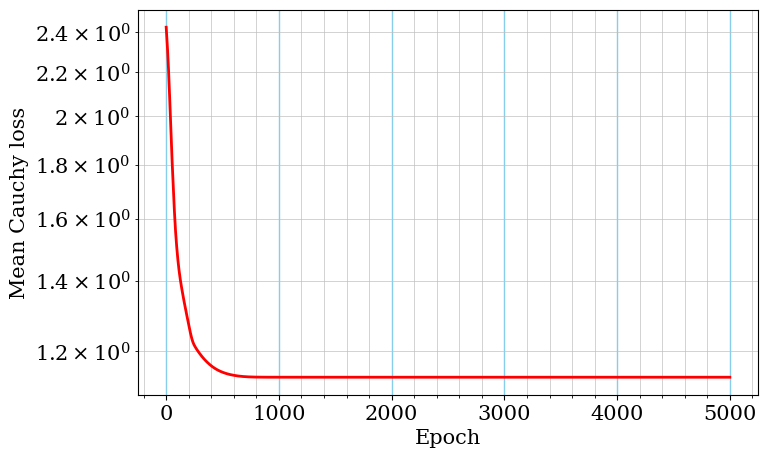

In [9]:
plt.figure(figsize=(8,5))
plt.plot(model.loss_history_, linewidth=2, color='red')
plt.xlabel('Epoch')
plt.ylabel('Mean Cauchy loss')
plt.yscale('log')
plt.grid()
plt.minorticks_on()
plt.grid(which='minor', linestyle='-', linewidth='0.5', color='silver')
plt.grid(which='major', linestyle='-', linewidth='1.0', color='skyblue')
plt.savefig('figures/cauchy_training_loss.pdf', format='pdf', bbox_inches='tight')
plt.show()

## Question 3

In [10]:
names = ["w0 (intercept)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]

# Ordinary least squares for comparison
Xd = np.column_stack([np.ones(len(y)), X])
w_ols = np.linalg.lstsq(Xd, y, rcond=None)[0]

coef_table = pd.DataFrame({"Cauchy (c=1)": model.w_, "OLS (for comparison)": w_ols}, index=names)
coef_table.round(4)

,Cauchy (c=1),OLS (for comparison)
w0 (intercept),511.5593,454.6093
w1 (AT),-2.0826,-1.9775
w2 (V),-0.2358,-0.2339
w3 (AP),0.0074,0.0621
w4 (RH),-0.1549,-0.1581


## Question 4

In [11]:
print("Final mean Cauchy loss (1/N sum):", round(model.loss(X, y), 4))
print("Final total Cauchy loss (sum)   :", round(model.loss(X, y, total=True), 2))
print("Mean Cauchy loss at the OLS coefficients:",
      round(np.mean(0.5 * np.log1p((y - Xd @ w_ols) ** 2)), 4))

Final mean Cauchy loss (1/N sum): 1.1348
Final total Cauchy loss (sum)   : 10857.52
Mean Cauchy loss at the OLS coefficients: 1.1444


## Question 5

In [12]:
lo, hi, se = model.conf_int(X, y, level=0.95)

In [16]:
ci = pd.DataFrame({
    "estimate": model.w_, "std err": se,
    "CI low": lo, "CI high": hi,
}, index=names)
ci.round(4)

,estimate,std err,CI low,CI high
w0 (intercept),511.5593,22.0773,468.2887,554.8300
w1 (AT),-2.0826,0.0310,-2.1434,-2.0217
w2 (V),-0.2358,0.0140,-0.2632,-0.2084
w3 (AP),0.0074,0.0215,-0.0348,0.0496
w4 (RH),-0.1549,0.0086,-0.1717,-0.1380


AT, V, and RH are statistically significant. Their intervals exclude zero, so each has a reliably non-zero effect on $PE$ after controlling for the other variables. AP is not significant with the other variables are in the model. Its interval spans zero, so the data does not show a reliable effect of ambient pressure.

## Question 6

In [17]:
resid = model.predict(X) - y     # y_hat - y, as asked

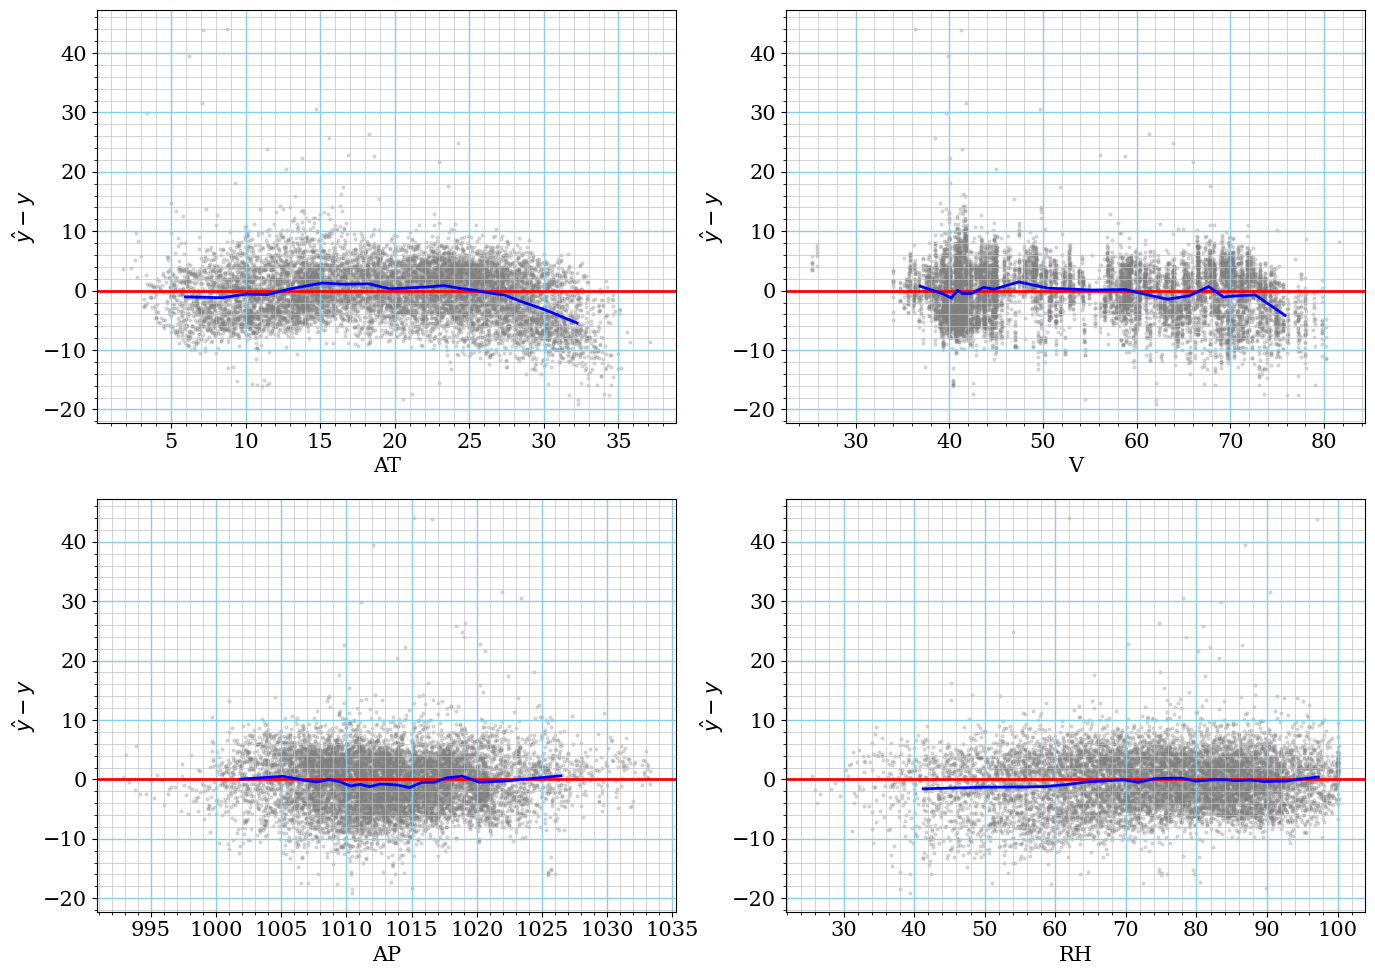

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, j, name in zip(axes.ravel(), range(4), features):
    ax.scatter(X[:, j], resid, s=4, alpha=0.25, color='gray')
    ax.axhline(0, color='red', linewidth=2)
    bins = pd.qcut(X[:, j], 20, duplicates="drop")
    gm = pd.DataFrame({"x": X[:, j], "r": resid}).groupby(bins, observed=True).mean()
    ax.plot(gm["x"], gm["r"], color='blue', linewidth=2)
    ax.set_xlabel(name)
    ax.set_ylabel('$\\hat{y} - y$')
    ax.minorticks_on()
    ax.grid(which='minor', linestyle='-', linewidth='0.5', color='silver')
    ax.grid(which='major', linestyle='-', linewidth='1.0', color='skyblue')
plt.tight_layout()
plt.savefig('figures/cauchy_residual_plots.pdf', format='pdf', bbox_inches='tight')
plt.show()

The residuals sit around zero and form a fairly uniform horizontal band. Teh data looks like it has reasonable homoscedasticity. RH shows slightly larger spread at low humidity.

There are mostly symmetric residuals with somewhat heavy tails. The linear model with the Cauchy loss seems lika a decent fit, but the curve in AT slight curve in V are places that need to be improved.

# Question 6

## Dataset
Bank Marketing dataset from the UCI Machine Learning Repository https://archive.ics.uci.edu/dataset/222/bank+marketing

It has records of marketing campaigns of a Portuguese banking institution, collected between 2008 and 2010.

## Features

| Feature | Type | Meaning |
|---|---|---|
| age | numeric | Age of the client |
| job | categorical | Type of job (admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed, unknown) |
| marital | categorical | Marital status (married, divorced (includes widowed), single) |
| education | categorical | Education level (primary, secondary, tertiary, unknown) |
| default | binary | Does the client have credit in default? |
| balance | numeric | Average yearly balance, in euros |
| housing | binary | Does the client have a housing loan? |
| loan | binary | Does the client have a personal loan? |
| contact | categorical | Contact communication type (cellular, telephone, unknown) |
| day_of_week | numeric | Day of the month (1 to 31) of the last contact (named day in the original CSV) |
| month | categorical | Month of the last contact |
| duration | numeric | Duration of the last contact, in seconds |
| campaign | numeric | Number of contacts performed during this campaign for this client (including the last one) |
| pdays | numeric | Number of days since the client was last contacted in a previous campaign ($-1$ means never contacted before) |
| previous | numeric | Number of contacts performed before this campaign for this client |
| poutcome | categorical | Outcome of the previous marketing campaign (success, failure, other, unknown) |

### Label

| Label | Meaning |
|---|---|
| `y` | Has the client subscribed to a term deposit? `yes` ($=1$, positive class) or `no` ($=0$) |

I simply just want to classify if the client has subscribed to a term deposit or not.

In [19]:
import os
import subprocess, sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 15

os.makedirs('figures', exist_ok=True)

In [20]:
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

try:
    bank = fetch_ucirepo(id=222)                      # Bank Marketing dataset
    df = pd.concat([bank.data.features, bank.data.targets], axis=1)
except Exception:
    try:
        df = pd.read_csv("bank-full.csv", sep=";")    # local copy of the original CSV
    except Exception:
        from google.colab import files
        up = files.upload()
        df = pd.read_csv(next(iter(up)), sep=";")

df = df.rename(columns={"day": "day_of_week"})          # the original CSV calls this column 'day'
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day_of_week,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,NaN,5,may,261,1,-1,0,NaN,no
1,44,technician,single,secondary,no,29,yes,no,NaN,5,may,151,1,-1,0,NaN,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,NaN,5,may,76,1,-1,0,NaN,no
3,47,blue-collar,married,NaN,no,1506,yes,no,NaN,5,may,92,1,-1,0,NaN,no
4,33,NaN,single,NaN,no,1,no,no,NaN,5,may,198,1,-1,0,NaN,no


In [21]:
print(df.shape)
df.info()

(45211, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   age          45211 non-null  int64 
 1   job          44923 non-null  object
 2   marital      45211 non-null  object
 3   education    43354 non-null  object
 4   default      45211 non-null  object
 5   balance      45211 non-null  int64 
 6   housing      45211 non-null  object
 7   loan         45211 non-null  object
 8   contact      32191 non-null  object
 9   day_of_week  45211 non-null  int64 
 10  month        45211 non-null  object
 11  duration     45211 non-null  int64 
 12  campaign     45211 non-null  int64 
 13  pdays        45211 non-null  int64 
 14  previous     45211 non-null  int64 
 15  poutcome     8252 non-null   object
 16  y            45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [22]:
categorical_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
df[categorical_cols] = df[categorical_cols].fillna("unknown")
df.isna().sum()

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day_of_week,0


     count  percent
y                  
no   39922     88.3
yes   5289     11.7

Imbalance ratio (majority : minority) = 7.55 : 1
Accuracy of a classifier that always predicts the majority class = 0.8830


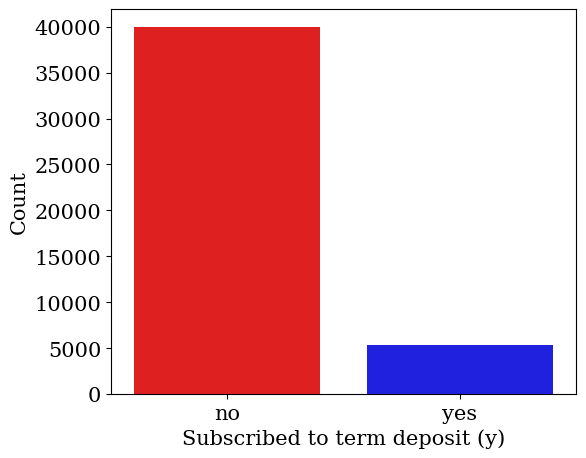

In [23]:
# Checking Class Imbalance
counts = df["y"].value_counts()
percent = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": counts, "percent": percent.round(2)}))
print()
print("Imbalance ratio (majority : minority) = %.2f : 1" % (counts.max() / counts.min()))
print("Accuracy of a classifier that always predicts the majority class = %.4f" % (counts.max() / counts.sum()))

plt.figure(figsize=(6,5))
sns.countplot(x=df["y"], palette=["red", "blue"], hue=df["y"], legend=False)
plt.xlabel('Subscribed to term deposit (y)')
plt.ylabel('Count')
plt.savefig('figures/bank_class_balance.pdf', format='pdf', bbox_inches='tight')
plt.show()

The data is imbalanced. Will use class-weighted cross entropy to try to compensate.

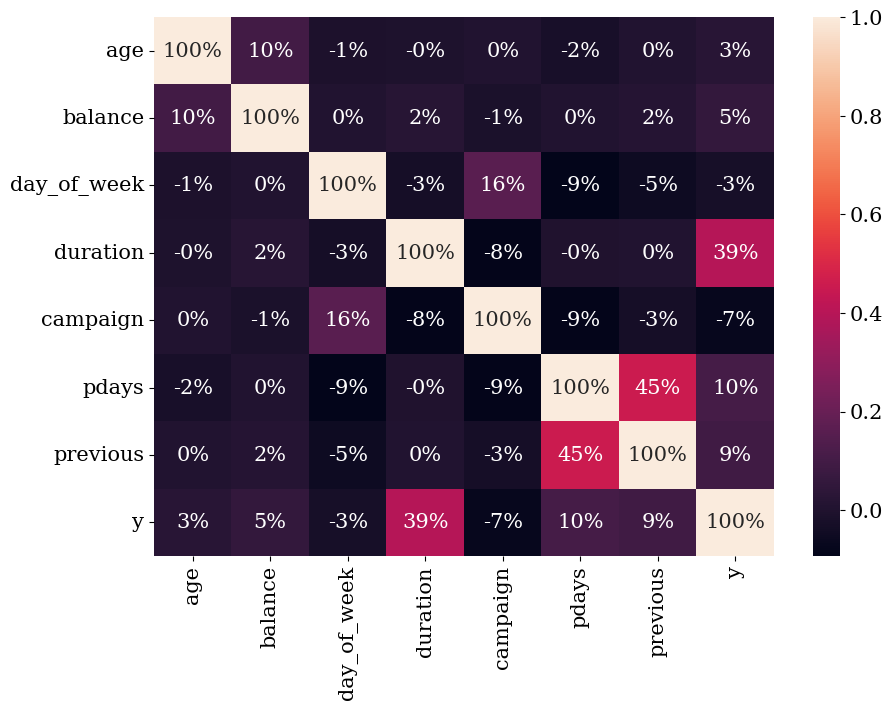

In [24]:
numeric_cols = ["age", "balance", "day_of_week", "duration", "campaign", "pdays", "previous"]
df_num = df[numeric_cols].copy()
df_num["y"] = (df["y"] == "yes").astype(int)

plt.figure(figsize=(10,7))
sns.heatmap(df_num.corr(), annot=True, fmt=".0%")
plt.savefig('figures/bank_correlation_heatmap.pdf', format='pdf', bbox_inches='tight')
plt.show()

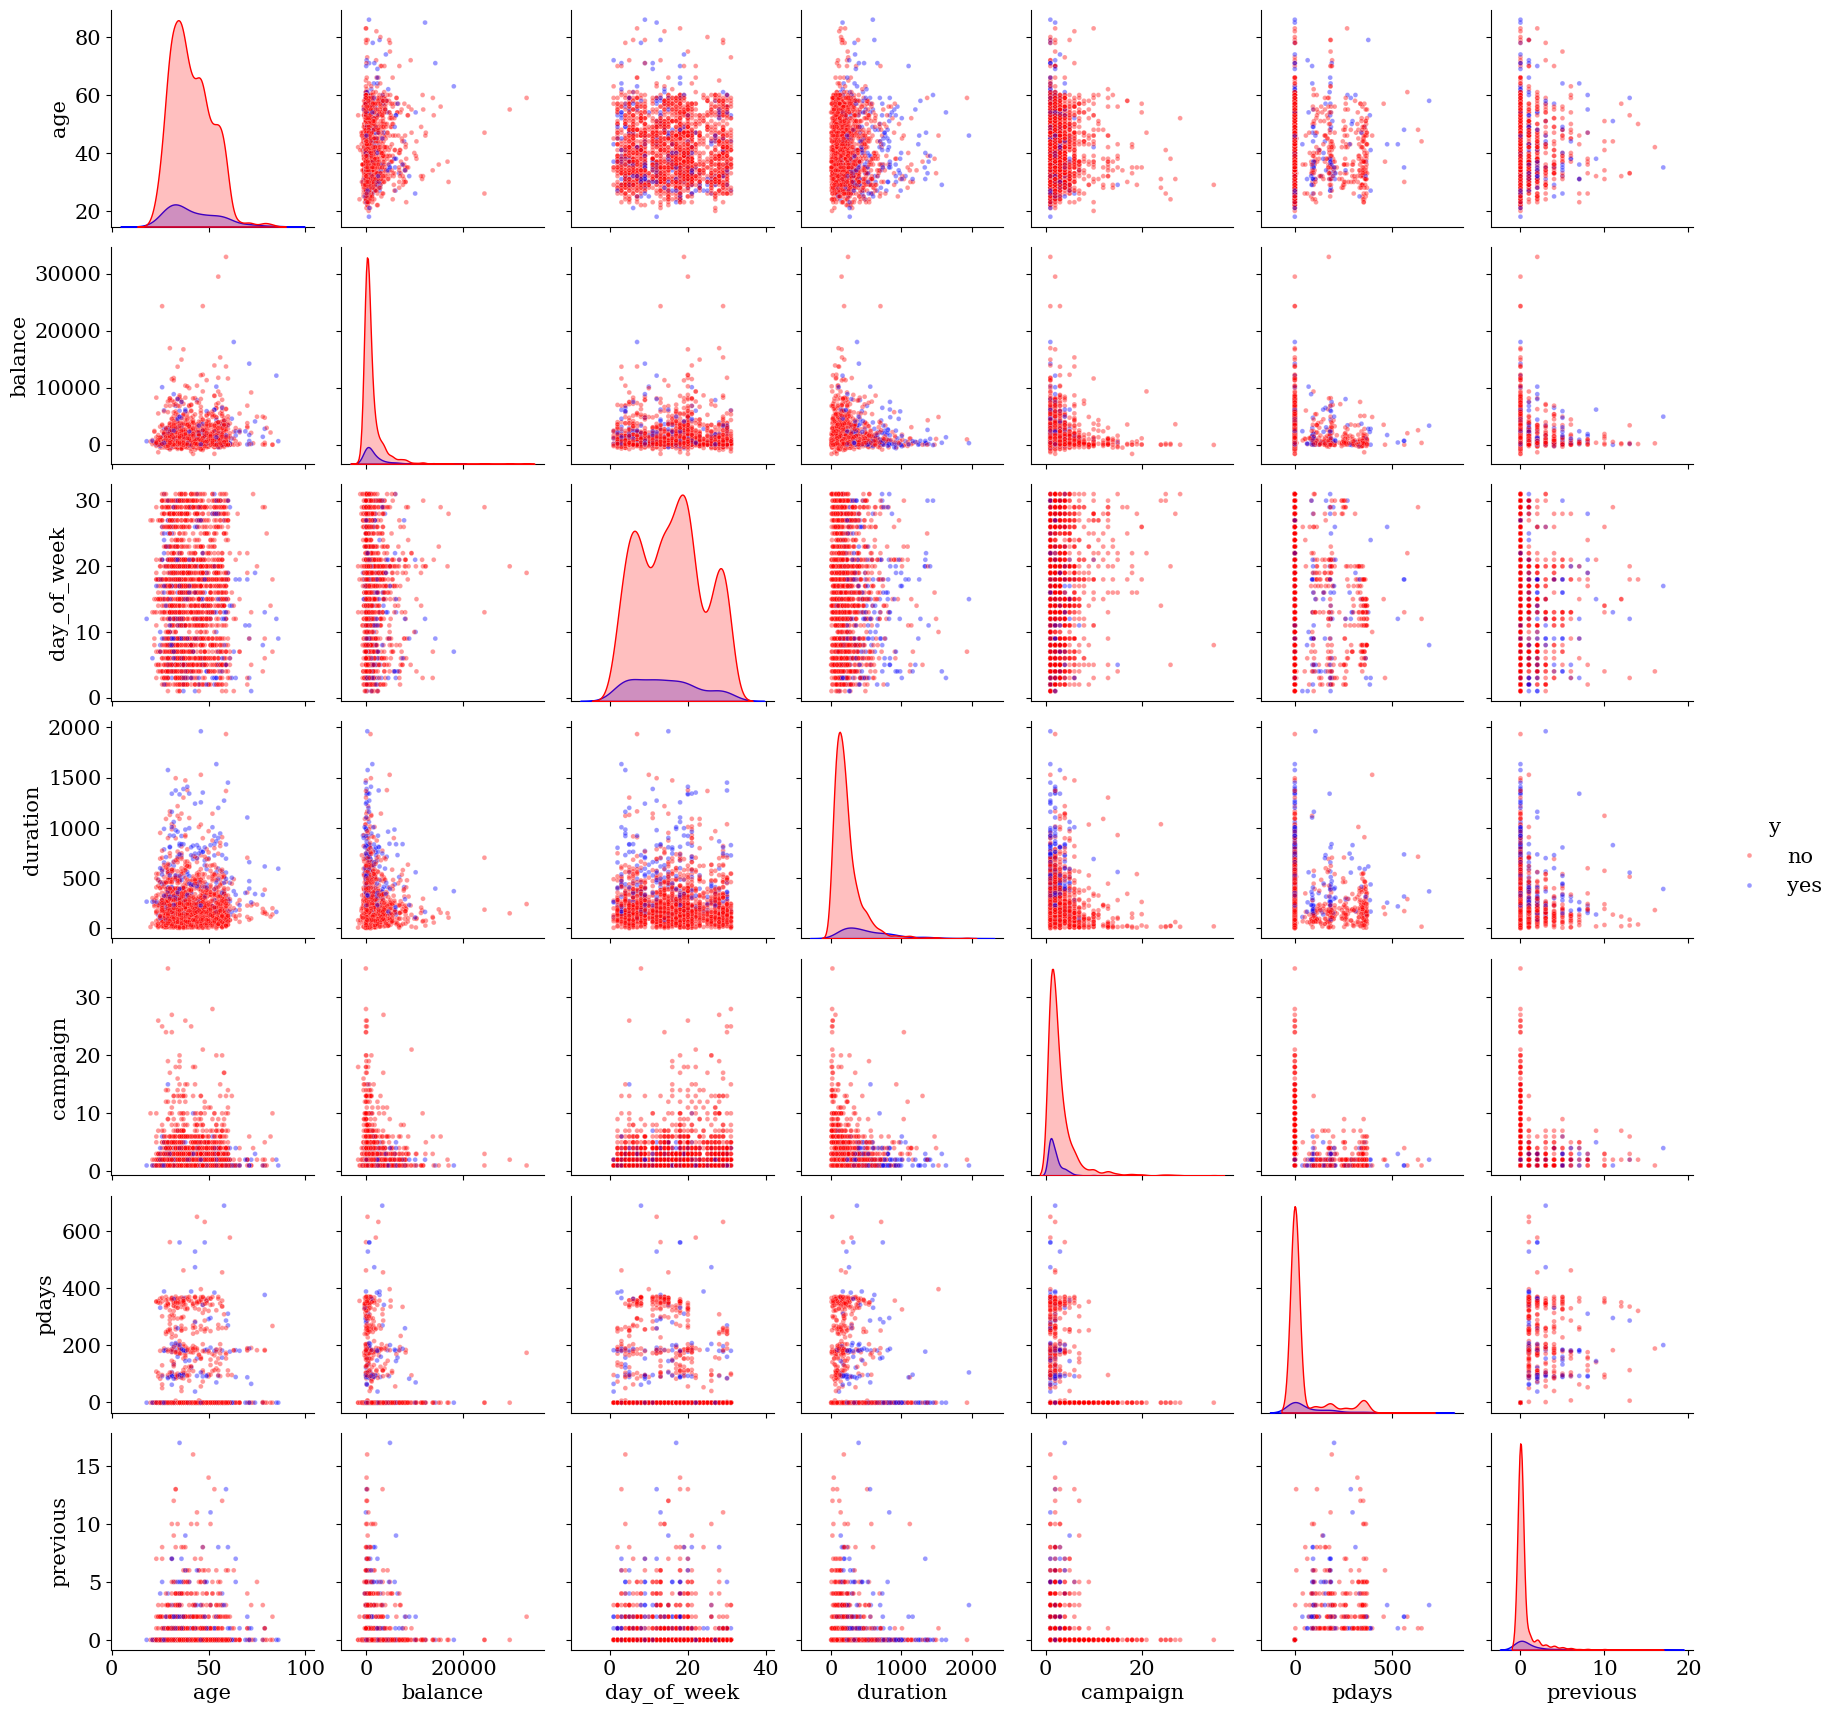

In [25]:
# Pairplot on a random sample since the full dataset has 45k points, which is slow to draw
sample = df[numeric_cols + ["y"]].sample(2000, random_state=734)
g = sns.pairplot(sample, hue="y", palette={"no": "red", "yes": "blue"}, plot_kws={"alpha": 0.4, "s": 12})
g.savefig('figures/bank_pairplot.pdf', format='pdf', bbox_inches='tight')
plt.show()

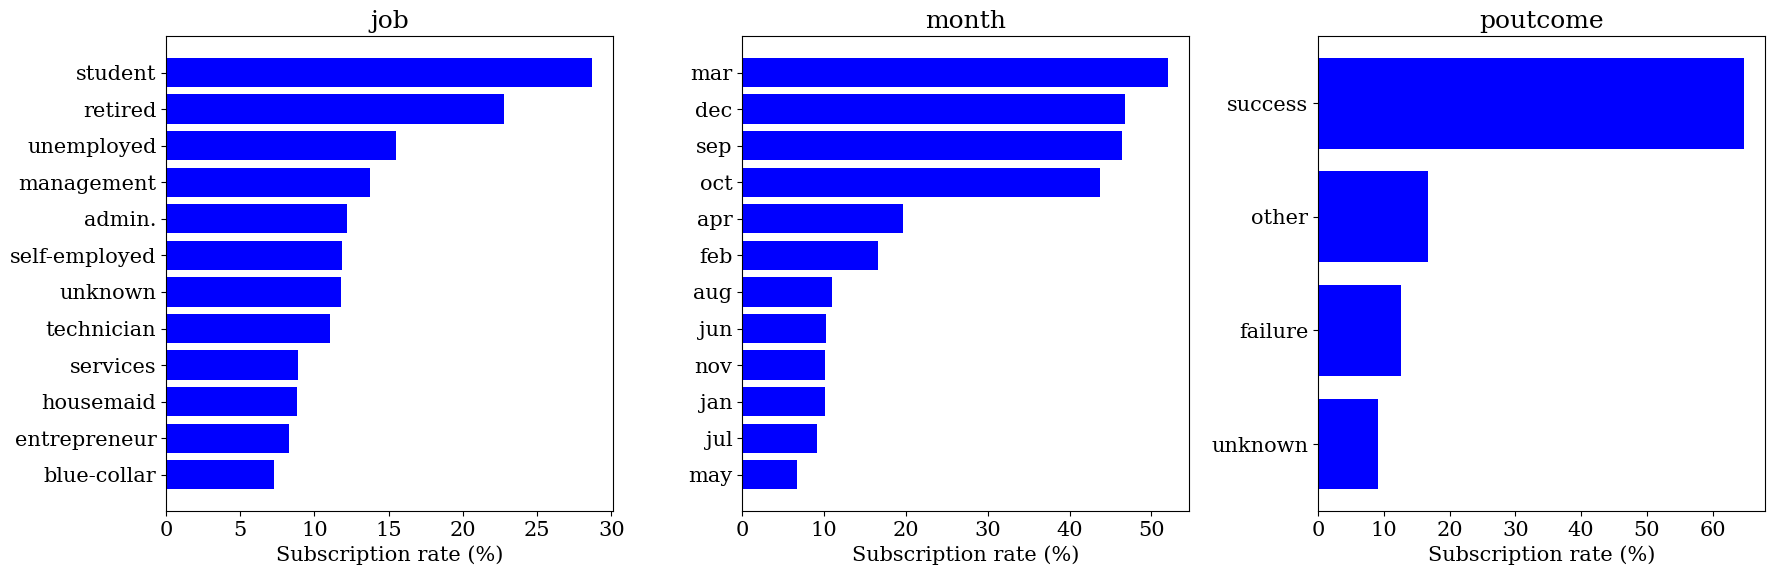

In [26]:
# Subscription rate for each category of a few categorical features
fig, axes = plt.subplots(1, 3, figsize=(18,6))
for ax, col in zip(axes, ["job", "month", "poutcome"]):
    rate = df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100).sort_values()
    ax.barh(rate.index, rate.values, color='blue')
    ax.set_xlabel('Subscription rate (%)')
    ax.set_title(col)
plt.tight_layout()
plt.savefig('figures/bank_subscription_rate.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [27]:
DROP_DURATION = True
features = df.drop(columns=["y"])
if DROP_DURATION:
    features = features.drop(columns=["duration"])

X = pd.get_dummies(features, columns=[c for c in categorical_cols if c in features.columns], drop_first=True, dtype=float)
Labels = df[["y"]]
print("Number of features after one-hot encoding:", X.shape[1])
X.head()

Number of features after one-hot encoding: 41


,age,balance,day_of_week,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,job_management,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,1,-1,0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,44,29,5,1,-1,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,33,2,5,1,-1,0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
3,47,1506,5,1,-1,0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,33,1,5,1,-1,0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Split the dataset into training and test sets
X_train, X_test, y_train_label, y_test_label = train_test_split(
    X, Labels, test_size=0.35, random_state=734, stratify=Labels)

In [31]:
# Standardize the features to have mean=0 and variance=1
scaler = StandardScaler().fit(X_train)

X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

In [44]:
# Reshape y_train and y_test to be 1D arrays and encode the labels as 0/1
y_train_label = np.ravel(y_train_label)
y_test_label = np.ravel(y_test_label)

encoder = LabelEncoder()
encoder.fit(y_train_label)
y_train = encoder.transform(y_train_label)
y_test = encoder.transform(y_test_label)

print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Positive rate in train: %.4f, in test: %.4f" % (y_train.mean(), y_test.mean()))

Train size: (29387, 41)  Test size: (15824, 41)
Positive rate in train: 0.1170, in test: 0.1170


In [33]:
import torch

torch.manual_seed(734)
np.random.seed(734)

def cross_entropy(h, y, pos_weight=1.0, eps=1e-12):
    # Binary cross-entropy written by hand (pos_weight = 1 gives the standard loss)
    h = h.clamp(eps, 1 - eps)
    return -(pos_weight * y * torch.log(h) + (1 - y) * torch.log(1 - h)).mean()


class LogisticsRegressionSGD:
    """Logistics regression trained by mini-batch SGD on the cross-entropy, using PyTorch."""

    def __init__(self, lr=0.1, epochs=30, batch_size=256, pos_weight=1.0, seed=734):
        self.lr, self.epochs, self.batch_size = lr, epochs, batch_size
        self.pos_weight, self.seed = pos_weight, seed

    @staticmethod
    def _add_bias(X):
        X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
        return torch.cat([torch.ones(X.shape[0], 1), X], dim=1)       # column of ones for the intercept

    def _h(self, Xb, theta):
        return torch.sigmoid(Xb @ theta)                               # h_theta(x) = g(theta^T x)

    def fit(self, X, y, X_val=None, y_val=None):
        torch.manual_seed(self.seed)
        Xb = self._add_bias(X)
        yt = torch.as_tensor(np.asarray(y), dtype=torch.float32)
        N = Xb.shape[0]
        self.theta = torch.zeros(Xb.shape[1], requires_grad=True)
        optimizer = torch.optim.SGD([self.theta], lr=self.lr)         # plain SGD, no momentum

        if X_val is not None:
            Xv, yv = self._add_bias(X_val), torch.as_tensor(np.asarray(y_val), dtype=torch.float32)
        self.train_loss_, self.val_loss_ = [], []

        for epoch in range(self.epochs):
            perm = torch.randperm(N)                                   # reshuffle every epoch
            for start in range(0, N, self.batch_size):
                idx = perm[start:start + self.batch_size]              # one mini-batch
                loss = cross_entropy(self._h(Xb[idx], self.theta), yt[idx], self.pos_weight)
                optimizer.zero_grad()
                loss.backward()                                        # autograd computes dJ/dtheta
                optimizer.step()                                       # theta <- theta - lr * grad

            with torch.no_grad():                                      # track the loss after each epoch
                self.train_loss_.append(cross_entropy(self._h(Xb, self.theta), yt, self.pos_weight).item())
                if X_val is not None:
                    self.val_loss_.append(cross_entropy(self._h(Xv, self.theta), yv, self.pos_weight).item())
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            return self._h(self._add_bias(X), self.theta).numpy()      # P(Y = 1 | X = x)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [34]:
Xb_chk = LogisticsRegressionSGD._add_bias(X_train[:1000])
y_chk = torch.as_tensor(y_train[:1000], dtype=torch.float32)
theta_chk = (0.1 * torch.randn(Xb_chk.shape[1])).requires_grad_()

h_chk = torch.sigmoid(Xb_chk @ theta_chk)
cross_entropy(h_chk, y_chk).backward()                                  # autograd gradient

analytic = Xb_chk.T @ (h_chk.detach() - y_chk) / len(y_chk)             # (1/N) X^T (h - y)
print("max |autograd - analytic| =", (theta_chk.grad - analytic).abs().max().item())

max |autograd - analytic| = 3.2782554626464844e-07


In [35]:
model = LogisticsRegressionSGD(lr=0.1, epochs=30, batch_size=256)
model.fit(X_train, y_train, X_test, y_test)
print("Final training loss: %.4f" % model.train_loss_[-1])
print("Final test loss    : %.4f" % model.val_loss_[-1])

Final training loss: 0.2987
Final test loss    : 0.3040


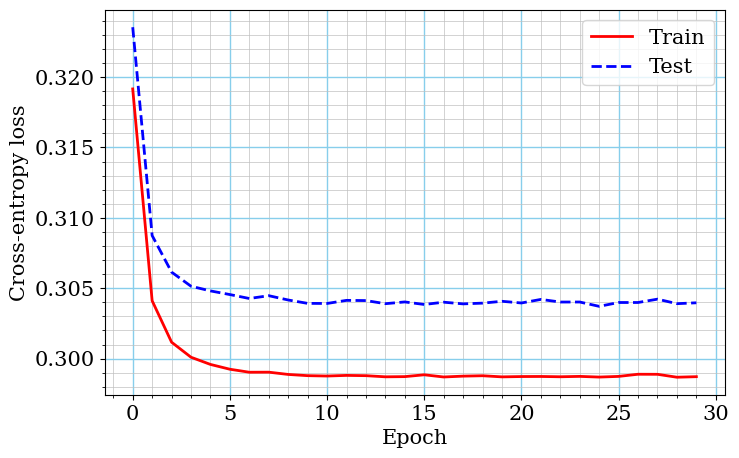

In [36]:
plt.figure(figsize=(8,5))
plt.plot(model.train_loss_, linewidth=2, color='red', label='Train')
plt.plot(model.val_loss_, linewidth=2, color='blue', linestyle='--', label='Test')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.grid()
plt.minorticks_on()
plt.grid(which='minor', linestyle='-', linewidth='0.5', color='silver')
plt.grid(which='major', linestyle='-', linewidth='1.0', color='skyblue')
plt.legend()
plt.savefig('figures/bank_loss_curve.pdf', format='pdf', bbox_inches='tight')
plt.show()

In [37]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()      # N_neg / N_pos
print("Positive-class weight: %.2f" % pos_weight)

model_w = LogisticsRegressionSGD(lr=0.1, epochs=30, batch_size=256, pos_weight=pos_weight)
model_w.fit(X_train, y_train, X_test, y_test)
print("Final training loss: %.4f" % model_w.train_loss_[-1])

Positive-class weight: 7.55
Final training loss: 1.0027


In [48]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, average_precision_score, precision_recall_curve)

def evaluate(name, y_true, proba, threshold=0.5):
    y_hat = (proba >= threshold).astype(int)
    print(name)
    print("Accuracy          :", round(accuracy_score(y_true, y_hat), 4))
    print("Balanced accuracy :", round(balanced_accuracy_score(y_true, y_hat), 4))
    print("ROC-AUC           :", round(roc_auc_score(y_true, proba), 4))
    print("Average precision :", round(average_precision_score(y_true, proba), 4))
    print("\nConfusion matrix (rows = true, columns = predicted):")
    print(confusion_matrix(y_true, y_hat))
    print("\n" + classification_report(y_true, y_hat, target_names=encoder.classes_, zero_division=0))
    return y_hat

proba = model.predict_proba(X_test)
proba_w = model_w.predict_proba(X_test)

y_hat = evaluate("SGD, standard cross-entropy", y_test, proba)

SGD, standard cross-entropy
Accuracy          : 0.8898
Balanced accuracy : 0.5767
ROC-AUC           : 0.763
Average precision : 0.3927

Confusion matrix (rows = true, columns = predicted):
[[13769   204]
 [ 1540   311]]

              precision    recall  f1-score   support

          no       0.90      0.99      0.94     13973
         yes       0.60      0.17      0.26      1851

    accuracy                           0.89     15824
   macro avg       0.75      0.58      0.60     15824
weighted avg       0.86      0.89      0.86     15824



In [49]:
y_hat_w = evaluate("SGD, class-weighted cross-entropy", y_test, proba_w)

SGD, class-weighted cross-entropy
Accuracy          : 0.7481
Balanced accuracy : 0.6961
ROC-AUC           : 0.7617
Average precision : 0.3881

Confusion matrix (rows = true, columns = predicted):
[[10675  3298]
 [  688  1163]]

              precision    recall  f1-score   support

          no       0.94      0.76      0.84     13973
         yes       0.26      0.63      0.37      1851

    accuracy                           0.75     15824
   macro avg       0.60      0.70      0.61     15824
weighted avg       0.86      0.75      0.79     15824



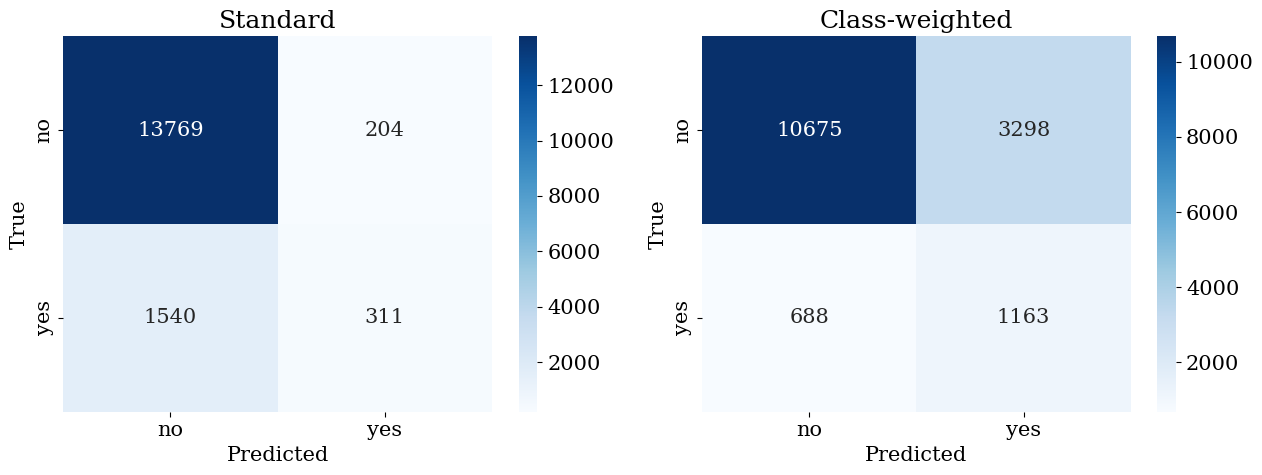

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
for ax, yh, title in zip(axes, [y_hat, y_hat_w], ["Standard", "Class-weighted"]):
    sns.heatmap(confusion_matrix(y_test, yh), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=encoder.classes_, yticklabels=encoder.classes_)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
plt.tight_layout()
plt.savefig('figures/bank_confusion_matrices.pdf', format='pdf', bbox_inches='tight')
plt.show()

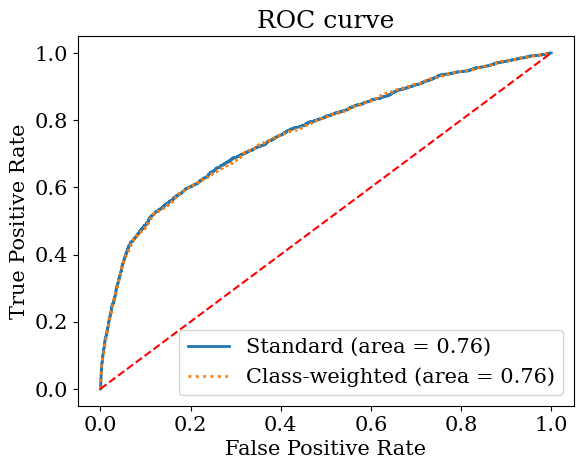

In [45]:
plt.figure()
for p, lbl, ls in [(proba, 'Standard', '-'), (proba_w, 'Class-weighted', ':')]:
    fpr, tpr, threshold = roc_curve(y_test, p)
    plt.plot(fpr, tpr, linestyle=ls, linewidth=2, label='%s (area = %0.2f)' % (lbl, roc_auc_score(y_test, p)))
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve')
plt.legend(loc='lower right')
plt.savefig('figures/bank_ROC_Curve.pdf', format='pdf', bbox_inches='tight')
plt.show()

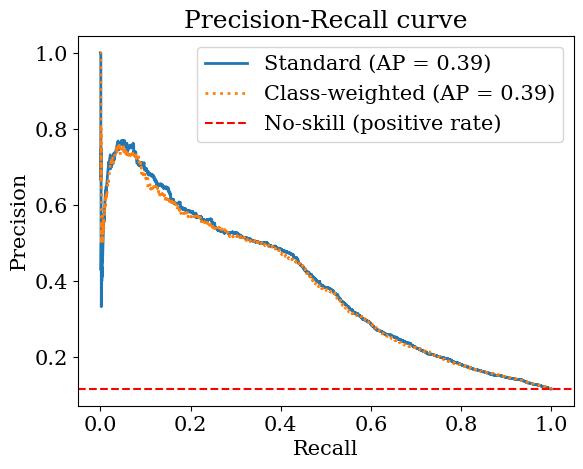

In [42]:
plt.figure()
for p, lbl, ls in [(proba, 'Standard', '-'), (proba_w, 'Class-weighted', ':')]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, linestyle=ls, linewidth=2, label='%s (AP = %0.2f)' % (lbl, average_precision_score(y_test, p)))
plt.axhline(y_test.mean(), color='red', linestyle='--', label='No-skill (positive rate)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve')
plt.legend(loc='upper right')
plt.savefig('figures/bank_PR_Curve.pdf', format='pdf', bbox_inches='tight')
plt.show()

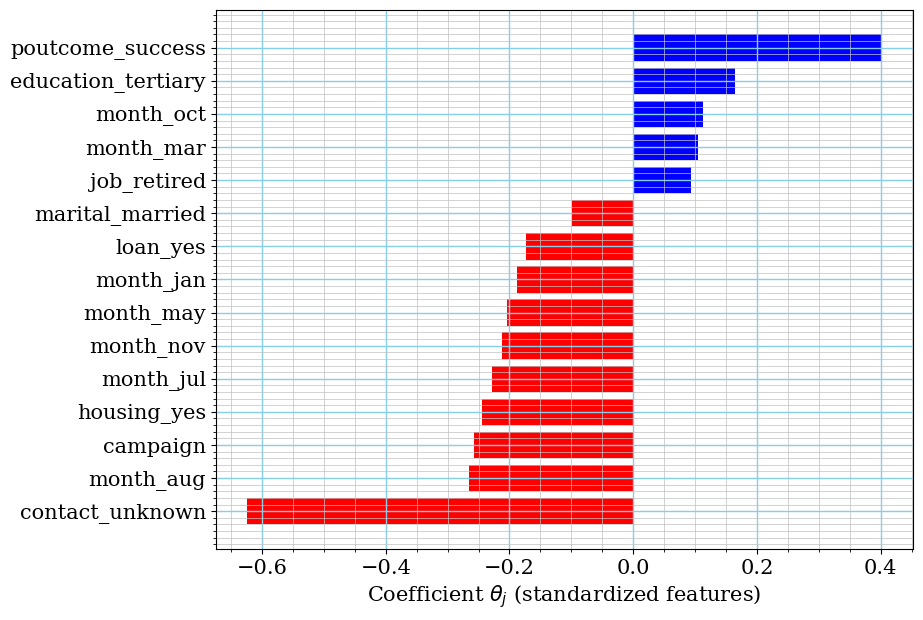

In [43]:
theta = model.theta.detach().numpy()
coef = pd.Series(theta[1:], index=X.columns)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15).sort_values()

plt.figure(figsize=(9,7))
plt.barh(top.index, top.values, color=['red' if v < 0 else 'blue' for v in top.values])
plt.xlabel(r'Coefficient $\theta_j$ (standardized features)')
plt.grid()
plt.minorticks_on()
plt.grid(which='minor', linestyle='-', linewidth='0.5', color='silver')
plt.grid(which='major', linestyle='-', linewidth='1.0', color='skyblue')
plt.savefig('figures/bank_top_coefficients.pdf', format='pdf', bbox_inches='tight')
plt.show()

## Findings

The dataset is imbalanced. Always answering no already gives a high accuracy, so accuracy alone doesn't show if the model is useful. For this reason, I also included balanced accuracy on top of the other metrics shown in the class example.

With the standard cross-entropy, the model tends to be conservative since it has high accuracy but misses many of the clients who would subscribe, since there was low recall for yes. Weighting the positive class makes the model find many more subscribers, since it has higher recall, at the cost of more false negatives, or lower precision. The ROC-AUC and average precision are similar for both models, because weighting mostly moves the decision threshold instead of changing how the clients are ranked.